# Proyecto final: Telecomunicaciones — Identificar operadores ineficaces

### Introducción: 

La eficiencia en la atención telefónica es un factor importante para las empresas que gestionan grandes volúmenes de llamadas. Un servicio de telefonía virtual requiere que sus operadores atiendan oportunamente las llamadas entrantes, reduzcan las llamadas perdidas y mantengan tiempos de espera adecuados para brindar una buena experiencia a los clientes.

En este proyecto se analizará una base de datos del servicio de telefonía virtual CallMeMaybe, que contiene información sobre las llamadas realizadas, su dirección, duración, estado, tipo de comunicación y actividad de los operadores. También se utilizará información sobre los clientes y sus planes tarifarios para explorar posibles diferencias en el comportamiento de las llamadas.

Mediante técnicas de análisis exploratorio de datos, visualización y pruebas de hipótesis estadísticas, se identificarán operadores que presenten señales de ineficacia, considerando la cantidad de llamadas entrantes perdidas, los tiempos de espera prolongados y el volumen de llamadas salientes. Los resultados permitirán generar recomendaciones para mejorar la distribución de llamadas, supervisar el desempeño de los operadores y optimizar la calidad del servicio.


### Objetivo general:

Analizar los datos del servicio de telefonía virtual CallMeMaybe para identificar operadores con posibles problemas de desempeño, mediante el análisis exploratorio de datos, la construcción de indicadores operativos y la aplicación de pruebas de hipótesis estadísticas.


### Objetivos específicos: 

- Examinar la estructura, calidad y características de los conjuntos de datos para identificar valores ausentes, registros duplicados e inconsistencias.
- Analizar la distribución de las llamadas según su dirección, tipo, duración y volumen diario.
- Calcular indicadores de desempeño por operador, incluyendo la tasa de llamadas entrantes perdidas, el tiempo de espera y el volumen de llamadas salientes.
- Identificar operadores que presenten múltiples señales de posible ineficacia y priorizarlos para una revisión operativa.
- Comparar los indicadores de llamadas entrantes entre los planes tarifarios mediante pruebas de hipótesis estadísticas.
- Formular conclusiones y recomendaciones basadas en los resultados para contribuir a mejorar la eficiencia operativa y la atención telefónica.


### Herramientas: 
- Python: lenguaje de programación utilizado para realizar el análisis y automatizar los cálculos.
- pandas: para cargar, limpiar, transformar, agrupar y analizar los conjuntos de datos.
- NumPy: para realizar operaciones numéricas y apoyar el cálculo de indicadores.
- Matplotlib: para crear histogramas, gráficos circulares y visualizaciones del comportamiento de las llamadas.
- SciPy: para aplicar pruebas estadísticas y evaluar diferencias entre grupos.
-Jupyter Notebook en Visual Studio Code: entorno de trabajo para documentar el procedimiento, ejecutar el código y presentar los resultados de manera organizada.


### Alcance: 

El análisis se realizará a partir de los dos conjuntos de datos disponibles: telecom_dataset_us.csv, que contiene información sobre las llamadas y los operadores, y telecom_clients_us.csv, que incluye información sobre los clientes y sus planes tarifarios.

El proyecto abarcará la exploración y limpieza de los datos, el análisis de los patrones de llamadas, la construcción de indicadores por operador, la identificación de posibles casos de ineficacia y la evaluación de hipótesis estadísticas relacionadas con los tiempos de espera y las llamadas perdidas.

Las conclusiones estarán limitadas a la información disponible en los conjuntos de datos. Debido a que no se proporcionan objetivos oficiales de desempeño para cada operador, los indicadores relativos se utilizarán como criterios exploratorios para priorizar revisiones, no como evidencia definitiva de un desempeño deficiente. Los resultados servirán como base para proponer mejoras en la supervisión y gestión de las operaciones telefónicas.

## 1. Preparación del entorno

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats

# Configurar la visualización de pandas
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda value: f'{value:,.2f}')

warnings.filterwarnings('ignore', category=FutureWarning)

# Definir las rutas de los archivos
DATA_DIR = Path.cwd()

TELECOM_PATH = DATA_DIR / 'telecom_dataset_new.csv'
CLIENTS_PATH = DATA_DIR / 'telecom_clients.csv'

# Verificar que los archivos existan
print('Carpeta de trabajo:', DATA_DIR)
print('Archivo de llamadas encontrado:', TELECOM_PATH.exists())
print('Archivo de clientes encontrado:', CLIENTS_PATH.exists())

# Cargar los datos
telecom = pd.read_csv(TELECOM_PATH)
clients = pd.read_csv(CLIENTS_PATH)

# Mostrar las dimensiones de las tablas
print('\nDimensiones de los datos de llamadas:', telecom.shape)
print('Dimensiones de los datos de clientes:', clients.shape)

# Mostrar las primeras filas
print('\nDatos de llamadas:')
display(telecom.head())

print('\nDatos de clientes:')
display(clients.head())

Carpeta de trabajo: c:\Users\quist\OneDrive\Documentos\Tripleten\FINAL_PROJECT_DA\Telecomunicaciones- operadores ineficaces
Archivo de llamadas encontrado: True
Archivo de clientes encontrado: True

Dimensiones de los datos de llamadas: (53902, 9)
Dimensiones de los datos de clientes: (732, 3)

Datos de llamadas:


,user_id,date,direction,internal,operator_id,is_missed_call,calls_count,call_duration,total_call_duration
0,166377,2019-08-04 00:00:00+03:00,in,False,NaN,True,2,0,4
1,166377,2019-08-05 00:00:00+03:00,out,True,"880,022.00",True,3,0,5
2,166377,2019-08-05 00:00:00+03:00,out,True,"880,020.00",True,1,0,1
3,166377,2019-08-05 00:00:00+03:00,out,True,"880,020.00",False,1,10,18
4,166377,2019-08-05 00:00:00+03:00,out,False,"880,022.00",True,3,0,25



Datos de clientes:


,user_id,tariff_plan,date_start
0,166713,A,2019-08-15
1,166901,A,2019-08-23
2,168527,A,2019-10-29
3,167097,A,2019-09-01
4,168193,A,2019-10-16


## 2. Carga de los datos:

In [2]:
if not TELECOM_PATH.exists() or not CLIENTS_PATH.exists():
    raise FileNotFoundError(
        'No se encontraron los dos CSV. Coloca ambos archivos en la carpeta del notebook '
        'o ajusta DATA_DIR en la sección 1.'
    )

telecom = pd.read_csv(TELECOM_PATH)
clients = pd.read_csv(CLIENTS_PATH)

print('Dimensiones del dataset de llamadas:', telecom.shape)
print('Dimensiones del dataset de clientes:', clients.shape)

display(telecom.head())
display(clients.head())

Dimensiones del dataset de llamadas: (53902, 9)
Dimensiones del dataset de clientes: (732, 3)


,user_id,date,direction,internal,operator_id,is_missed_call,calls_count,call_duration,total_call_duration
0,166377,2019-08-04 00:00:00+03:00,in,False,NaN,True,2,0,4
1,166377,2019-08-05 00:00:00+03:00,out,True,"880,022.00",True,3,0,5
2,166377,2019-08-05 00:00:00+03:00,out,True,"880,020.00",True,1,0,1
3,166377,2019-08-05 00:00:00+03:00,out,True,"880,020.00",False,1,10,18
4,166377,2019-08-05 00:00:00+03:00,out,False,"880,022.00",True,3,0,25


,user_id,tariff_plan,date_start
0,166713,A,2019-08-15
1,166901,A,2019-08-23
2,168527,A,2019-10-29
3,167097,A,2019-09-01
4,168193,A,2019-10-16


## 3. Revisión inicial y calidad de los datos:

In [3]:
print('--- Información del dataset de llamadas ---')
telecom.info()

print('\\n--- Información del dataset de clientes ---')
clients.info()

print('\\nValores ausentes por columna: llamadas')
display(telecom.isna().sum().to_frame('valores_ausentes'))

print('Valores ausentes por columna: clientes')
display(clients.isna().sum().to_frame('valores_ausentes'))

print('Filas duplicadas en llamadas:', telecom.duplicated().sum())
print('Filas duplicadas en clientes:', clients.duplicated().sum())

print('\\nEstadísticas descriptivas de llamadas:')
display(telecom.describe(include='all').T)

--- Información del dataset de llamadas ---
<class 'pandas.DataFrame'>
RangeIndex: 53902 entries, 0 to 53901
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   user_id              53902 non-null  int64  
 1   date                 53902 non-null  str    
 2   direction            53902 non-null  str    
 3   internal             53785 non-null  object 
 4   operator_id          45730 non-null  float64
 5   is_missed_call       53902 non-null  bool   
 6   calls_count          53902 non-null  int64  
 7   call_duration        53902 non-null  int64  
 8   total_call_duration  53902 non-null  int64  
dtypes: bool(1), float64(1), int64(4), object(1), str(2)
memory usage: 3.3+ MB
\n--- Información del dataset de clientes ---
<class 'pandas.DataFrame'>
RangeIndex: 732 entries, 0 to 731
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   user_i

,valores_ausentes
user_id,0
date,0
direction,0
internal,117
operator_id,8172
is_missed_call,0
calls_count,0
call_duration,0
total_call_duration,0


Valores ausentes por columna: clientes


,valores_ausentes
user_id,0
tariff_plan,0
date_start,0


Filas duplicadas en llamadas: 4900
Filas duplicadas en clientes: 0
\nEstadísticas descriptivas de llamadas:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
user_id,"53,902.00",NaN,NaN,NaN,"167,295.34",598.88,"166,377.00","166,782.00","167,162.00","167,819.00","168,606.00"
date,53902,119,2019-11-25 00:00:00+03:00,1220,NaN,NaN,NaN,NaN,NaN,NaN,NaN
direction,53902,2,out,31917,NaN,NaN,NaN,NaN,NaN,NaN,NaN
internal,53785,2,False,47621,NaN,NaN,NaN,NaN,NaN,NaN,NaN
operator_id,"45,730.00",NaN,NaN,NaN,"916,535.99","21,254.12","879,896.00","900,788.00","913,938.00","937,708.00","973,286.00"
is_missed_call,53902,2,False,30334,NaN,NaN,NaN,NaN,NaN,NaN,NaN
calls_count,"53,902.00",NaN,NaN,NaN,16.45,62.92,1.00,1.00,4.00,12.00,"4,817.00"
call_duration,"53,902.00",NaN,NaN,NaN,866.68,"3,731.79",0.00,0.00,38.00,572.00,"144,395.00"
total_call_duration,"53,902.00",NaN,NaN,NaN,"1,157.13","4,403.47",0.00,47.00,210.00,902.00,"166,155.00"


In [4]:
# Trabajamos sobre copias para conservar los datos originales sin modificar.
calls = telecom.copy()
client_info = clients.copy()

# Normalizar nombres de columnas y valores de texto.
calls.columns = calls.columns.str.strip()
client_info.columns = client_info.columns.str.strip()

for col in ['direction', 'internal', 'is_missed_call']:
    if col in calls.columns:
        calls[col] = calls[col].astype('string').str.strip().str.lower()

# Convertir fechas.
calls['date'] = pd.to_datetime(calls['date'], errors='coerce')
client_info['date_start'] = pd.to_datetime(client_info['date_start'], errors='coerce')

# Convertir campos numéricos.
numeric_columns = ['calls_count', 'call_duration', 'total_call_duration', 'operator_id', 'user_id']
for col in numeric_columns:
    if col in calls.columns:
        calls[col] = pd.to_numeric(calls[col], errors='coerce')

client_info['user_id'] = pd.to_numeric(client_info['user_id'], errors='coerce')

# Eliminar filas completamente duplicadas.
calls = calls.drop_duplicates().copy()
client_info = client_info.drop_duplicates().copy()

print('Dimensiones de llamadas después de quitar duplicados:', calls.shape)
print('Dimensiones de clientes después de quitar duplicados:', client_info.shape)
display(calls.head())

Dimensiones de llamadas después de quitar duplicados: (49002, 9)
Dimensiones de clientes después de quitar duplicados: (732, 3)


,user_id,date,direction,internal,operator_id,is_missed_call,calls_count,call_duration,total_call_duration
0,166377,2019-08-04 00:00:00+03:00,in,false,NaN,true,2,0,4
1,166377,2019-08-05 00:00:00+03:00,out,true,"880,022.00",true,3,0,5
2,166377,2019-08-05 00:00:00+03:00,out,true,"880,020.00",true,1,0,1
3,166377,2019-08-05 00:00:00+03:00,out,true,"880,020.00",false,1,10,18
4,166377,2019-08-05 00:00:00+03:00,out,false,"880,022.00",true,3,0,25


## 4. Limpieza y creación de variables:

In [5]:
# Revisar categorías observadas antes de normalizar la interpretación.
for col in ['direction', 'internal', 'is_missed_call']:
    print(f'\\nValores únicos de {col}:')
    display(calls[col].value_counts(dropna=False).to_frame('registros'))

# Normalizar indicadores booleanos que suelen aparecer como True/False o 'true'/'false'.
def normalize_boolean(series):
    mapping = {
        'true': True, 'false': False,
        '1': True, '0': False,
        'yes': True, 'no': False,
        't': True, 'f': False
    }
    return series.astype('string').str.strip().str.lower().map(mapping)

calls['internal_bool'] = normalize_boolean(calls['internal'])
calls['missed_bool'] = normalize_boolean(calls['is_missed_call'])

# Espera aproximada = duración total menos duración de conversación.
# Se limita a cero cualquier resultado negativo por posibles inconsistencias del registro.
calls['waiting_time'] = (calls['total_call_duration'] - calls['call_duration']).clip(lower=0)

# Fecha sin hora para análisis diario.
calls['call_date'] = calls['date'].dt.date

# Revisar duraciones no válidas o registros sin operador.
quality_check = pd.DataFrame({
    'indicador': [
        'Duración de llamada negativa',
        'Duración total negativa',
        'Tiempo de espera calculado negativo antes de limitar',
        'Registros sin operador',
        'Registros sin fecha'
    ],
    'cantidad': [
        (calls['call_duration'] < 0).sum(),
        (calls['total_call_duration'] < 0).sum(),
        ((calls['total_call_duration'] - calls['call_duration']) < 0).sum(),
        calls['operator_id'].isna().sum(),
        calls['date'].isna().sum()
    ]
})
display(quality_check)

\nValores únicos de direction:


,registros
direction,
out,28999
in,20003


\nValores únicos de internal:


,registros
internal,
false,43239
true,5653
<NA>,110


\nValores únicos de is_missed_call:


,registros
is_missed_call,
false,27549
true,21453


,indicador,cantidad
0,Duración de llamada negativa,0
1,Duración total negativa,0
2,Tiempo de espera calculado negativo antes de l...,0
3,Registros sin operador,7456
4,Registros sin fecha,0


## 5. Análisis exploratorio de datos (EDA):

### 5.1. Volumen y dirección de las llamadas:

,total_llamadas
direction,
out,608864
in,197845


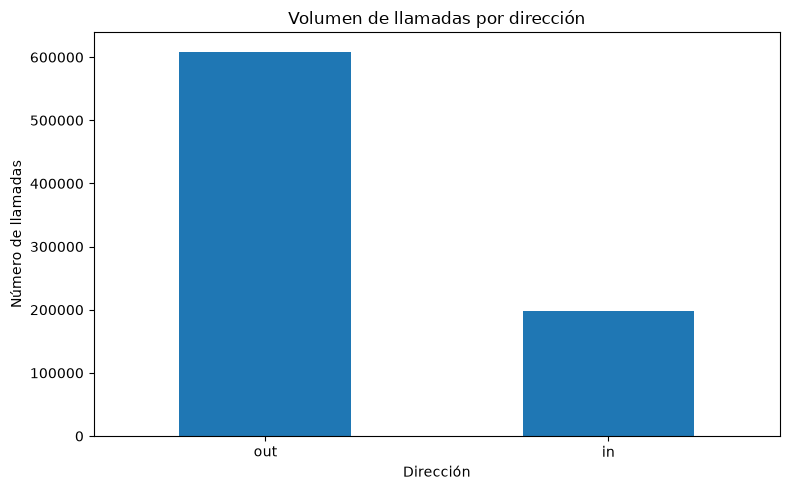

In [6]:
direction_counts = calls.groupby('direction', dropna=False)['calls_count'].sum().sort_values(ascending=False)
display(direction_counts.to_frame('total_llamadas'))

fig, ax = plt.subplots(figsize=(8, 5))
direction_counts.plot(kind='bar', ax=ax)
ax.set_title('Volumen de llamadas por dirección')
ax.set_xlabel('Dirección')
ax.set_ylabel('Número de llamadas')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

### 5.2. Distribución de duración de las llamadas:

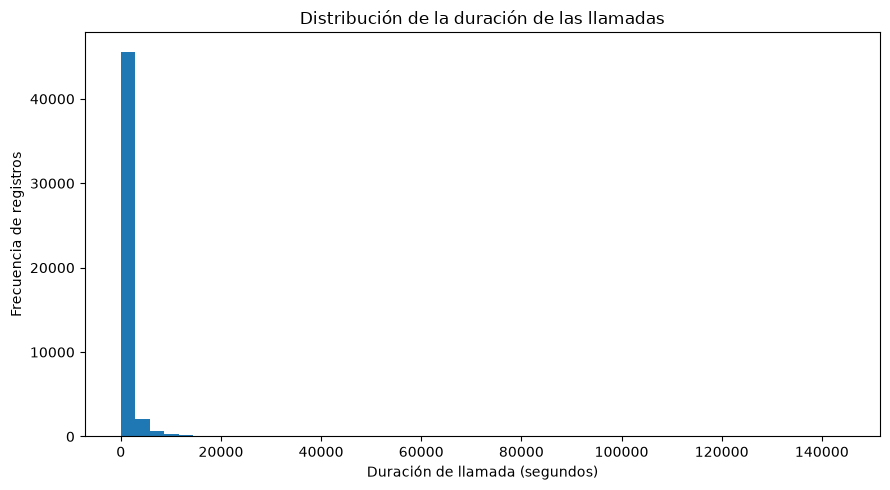

,duración_segundos
count,"49,002.00"
mean,866.28
std,"3,775.50"
min,0.00
25%,0.00
50%,37.00
75%,570.00
max,"144,395.00"


In [7]:
duration_data = calls.loc[calls['call_duration'].notna() & (calls['call_duration'] >= 0), 'call_duration']

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(duration_data, bins=50)
ax.set_title('Distribución de la duración de las llamadas')
ax.set_xlabel('Duración de llamada (segundos)')
ax.set_ylabel('Frecuencia de registros')
plt.tight_layout()
plt.show()

display(duration_data.describe().to_frame('duración_segundos'))

### 5.3. Participación de llamadas internas y externas:

,total_llamadas
tipo_llamada,
Externas,791829
Internas,14655
Sin dato,225


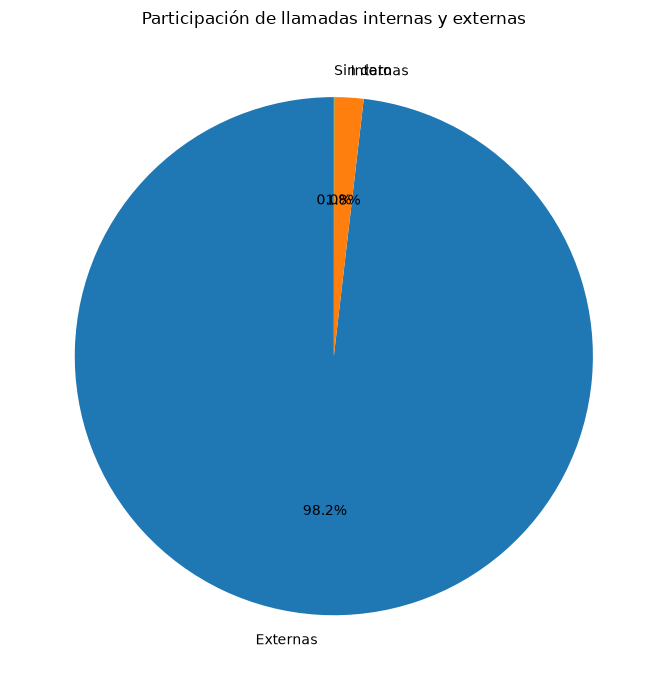

In [8]:
internal_labels = calls['internal_bool'].map({True: 'Internas', False: 'Externas'}).fillna('Sin dato')
internal_counts = calls.assign(tipo_llamada=internal_labels).groupby('tipo_llamada')['calls_count'].sum()

display(internal_counts.to_frame('total_llamadas'))

fig, ax = plt.subplots(figsize=(7, 7))
internal_counts.plot(kind='pie', autopct='%1.1f%%', startangle=90, ax=ax)
ax.set_title('Participación de llamadas internas y externas')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

### 5.4. Llamadas por día:

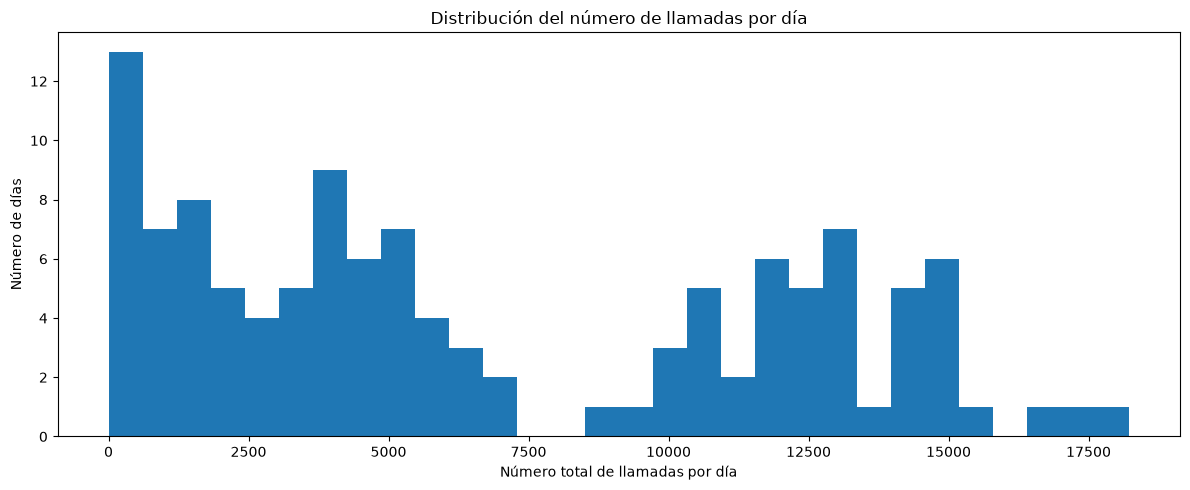

,llamadas_por_día
count,119.00
mean,"6,779.07"
std,"5,252.25"
min,2.00
25%,"2,170.00"
50%,"5,096.00"
75%,"11,851.50"
max,"18,222.00"


In [9]:
daily_calls = calls.dropna(subset=['call_date']).groupby('call_date')['calls_count'].sum().sort_index()

fig, ax = plt.subplots(figsize=(12, 5))
ax.hist(daily_calls, bins=30)
ax.set_title('Distribución del número de llamadas por día')
ax.set_xlabel('Número total de llamadas por día')
ax.set_ylabel('Número de días')
plt.tight_layout()
plt.show()

display(daily_calls.describe().to_frame('llamadas_por_día'))

### 5.5. Llamadas perdidas y tiempo de espera:

In [10]:
incoming = calls[calls['direction'].eq('in')].copy()

incoming_summary = pd.DataFrame({
    'métrica': ['Registros entrantes', 'Llamadas entrantes contabilizadas', 'Registros marcados como perdidos',
                'Tiempo de espera medio (segundos)', 'Tiempo de espera mediano (segundos)'],
    'valor': [
        len(incoming),
        incoming['calls_count'].sum(),
        incoming.loc[incoming['missed_bool'].eq(True), 'calls_count'].sum(),
        incoming['waiting_time'].mean(),
        incoming['waiting_time'].median()
    ]
})
display(incoming_summary)

,métrica,valor
0,Registros entrantes,"20,003.00"
1,Llamadas entrantes contabilizadas,"197,845.00"
2,Registros marcados como perdidos,"104,323.00"
3,Tiempo de espera medio (segundos),124.83
4,Tiempo de espera mediano (segundos),37.00


## 6. Indicadores de desempeño por operador:

In [11]:
# Resumen de llamadas entrantes por operador.
incoming_by_operator = incoming.groupby('operator_id').agg(
    incoming_calls=('calls_count', 'sum'),
    incoming_missed_calls=('calls_count', lambda s: s[incoming.loc[s.index, 'missed_bool'].eq(True)].sum()),
    mean_incoming_wait=('waiting_time', 'mean'),
    median_incoming_wait=('waiting_time', 'median'),
    incoming_records=('calls_count', 'size')
)

incoming_by_operator['incoming_missed_rate'] = (
    incoming_by_operator['incoming_missed_calls'] /
    incoming_by_operator['incoming_calls'].replace(0, np.nan)
)

# Resumen de llamadas salientes.
outgoing = calls[calls['direction'].eq('out')].copy()
outgoing_by_operator = outgoing.groupby('operator_id').agg(
    outgoing_calls=('calls_count', 'sum'),
    outgoing_records=('calls_count', 'size')
)

# Incluir todos los operadores con actividad identificada en cualquier dirección.
operator_metrics = incoming_by_operator.join(outgoing_by_operator, how='outer')
operator_metrics[['incoming_calls', 'incoming_missed_calls', 'outgoing_calls',
                  'incoming_records', 'outgoing_records']] = operator_metrics[
    ['incoming_calls', 'incoming_missed_calls', 'outgoing_calls',
     'incoming_records', 'outgoing_records']
].fillna(0)

operator_metrics['incoming_missed_rate'] = operator_metrics['incoming_missed_rate'].fillna(0)

# Umbrales exploratorios basados en cuartiles.
valid_missed_rates = operator_metrics.loc[operator_metrics['incoming_calls'] > 0, 'incoming_missed_rate']
valid_waits = operator_metrics.loc[operator_metrics['incoming_calls'] > 0, 'mean_incoming_wait'].dropna()
valid_outgoing = operator_metrics.loc[operator_metrics['outgoing_calls'] > 0, 'outgoing_calls']

missed_rate_threshold = valid_missed_rates.quantile(0.75) if len(valid_missed_rates) else np.nan
wait_threshold = valid_waits.quantile(0.75) if len(valid_waits) else np.nan
low_outgoing_threshold = valid_outgoing.quantile(0.25) if len(valid_outgoing) else np.nan

operator_metrics['high_missed_rate'] = (
    (operator_metrics['incoming_calls'] > 0) &
    (operator_metrics['incoming_missed_rate'] >= missed_rate_threshold)
)
operator_metrics['long_incoming_wait'] = (
    (operator_metrics['incoming_calls'] > 0) &
    (operator_metrics['mean_incoming_wait'] >= wait_threshold)
)
operator_metrics['low_outgoing_volume'] = (
    (operator_metrics['outgoing_calls'] > 0) &
    (operator_metrics['outgoing_calls'] <= low_outgoing_threshold)
)

# No se considera la ausencia de llamadas salientes como volumen bajo:
# puede significar que el operador no tiene esa función asignada.
operator_metrics['inefficiency_signals'] = operator_metrics[
    ['high_missed_rate', 'long_incoming_wait', 'low_outgoing_volume']
].sum(axis=1)

operator_metrics['potentially_inefficient'] = operator_metrics['inefficiency_signals'] >= 2

print(f'Umbral de tasa alta de llamadas perdidas (P75): {missed_rate_threshold:.2%}' if pd.notna(missed_rate_threshold) else 'No se pudo calcular el umbral de llamadas perdidas.')
print(f'Umbral de espera media entrante (P75): {wait_threshold:.2f} segundos' if pd.notna(wait_threshold) else 'No se pudo calcular el umbral de espera.')
print(f'Umbral de volumen saliente bajo (P25): {low_outgoing_threshold:.2f} llamadas' if pd.notna(low_outgoing_threshold) else 'No se pudo calcular el umbral de llamadas salientes.')

display(operator_metrics.sort_values(
    ['potentially_inefficient', 'inefficiency_signals', 'incoming_missed_rate'],
    ascending=[False, False, False]
).head(20))

Umbral de tasa alta de llamadas perdidas (P75): 0.67%
Umbral de espera media entrante (P75): 58.00 segundos
Umbral de volumen saliente bajo (P25): 11.00 llamadas


,incoming_calls,incoming_missed_calls,mean_incoming_wait,median_incoming_wait,incoming_records,incoming_missed_rate,outgoing_calls,outgoing_records,high_missed_rate,long_incoming_wait,low_outgoing_volume,inefficiency_signals,potentially_inefficient
operator_id,,,,,,,,,,,,,
"919,206.00",926.00,9.00,388.05,457.00,19.00,0.01,1.00,1.00,True,True,True,3,True
"919,554.00","1,182.00",11.00,503.16,539.50,76.00,0.01,11.00,8.00,True,True,True,3,True
"919,204.00","1,167.00",9.00,550.94,634.00,17.00,0.01,9.00,7.00,True,True,True,3,True
"904,344.00",4.00,3.00,27.50,27.50,2.00,0.75,5.00,1.00,True,False,True,2,True
"937,368.00",22.00,4.00,40.85,25.00,13.00,0.18,10.00,4.00,True,False,True,2,True
"944,226.00",180.00,30.00,153.58,95.50,50.00,0.17,109.00,38.00,True,True,False,2,True
"905,862.00",102.00,15.00,31.49,15.00,37.00,0.15,1.00,1.00,True,False,True,2,True
"941,844.00",7.00,1.00,29.25,24.50,4.00,0.14,11.00,6.00,True,False,True,2,True
"918,888.00",8.00,1.00,9.38,6.50,8.00,0.12,3.00,3.00,True,False,True,2,True


### 6.1. Lista priorizada de operadores para revisión:

In [12]:
operator_review = operator_metrics.reset_index().rename(columns={'operator_id': 'operator_id'})
operator_review['incoming_missed_rate_pct'] = operator_review['incoming_missed_rate'] * 100

review_columns = [
    'operator_id', 'incoming_calls', 'incoming_missed_calls', 'incoming_missed_rate_pct',
    'mean_incoming_wait', 'median_incoming_wait', 'outgoing_calls',
    'high_missed_rate', 'long_incoming_wait', 'low_outgoing_volume',
    'inefficiency_signals', 'potentially_inefficient'
]
operator_review = operator_review[review_columns].sort_values(
    ['potentially_inefficient', 'inefficiency_signals', 'incoming_missed_rate_pct'],
    ascending=[False, False, False]
)

display(operator_review.head(30))

print('Operadores evaluados:', operator_review['operator_id'].nunique())
print('Operadores con al menos dos señales:', operator_review['potentially_inefficient'].sum())

,operator_id,incoming_calls,incoming_missed_calls,incoming_missed_rate_pct,mean_incoming_wait,median_incoming_wait,outgoing_calls,high_missed_rate,long_incoming_wait,low_outgoing_volume,inefficiency_signals,potentially_inefficient
439,"919,206.00",926.00,9.00,0.97,388.05,457.00,1.00,True,True,True,3,True
465,"919,554.00","1,182.00",11.00,0.93,503.16,539.50,11.00,True,True,True,3,True
438,"919,204.00","1,167.00",9.00,0.77,550.94,634.00,9.00,True,True,True,3,True
242,"904,344.00",4.00,3.00,75.00,27.50,27.50,5.00,True,False,True,2,True
675,"937,368.00",22.00,4.00,18.18,40.85,25.00,10.00,True,False,True,2,True
823,"944,226.00",180.00,30.00,16.67,153.58,95.50,109.00,True,True,False,2,True
263,"905,862.00",102.00,15.00,14.71,31.49,15.00,1.00,True,False,True,2,True
812,"941,844.00",7.00,1.00,14.29,29.25,24.50,11.00,True,False,True,2,True
419,"918,888.00",8.00,1.00,12.50,9.38,6.50,3.00,True,False,True,2,True
557,"926,872.00",24.00,3.00,12.50,1.46,1.00,7.00,True,False,True,2,True


Operadores evaluados: 1092
Operadores con al menos dos señales: 97


### 6.2. Visualización de indicadores por operador:

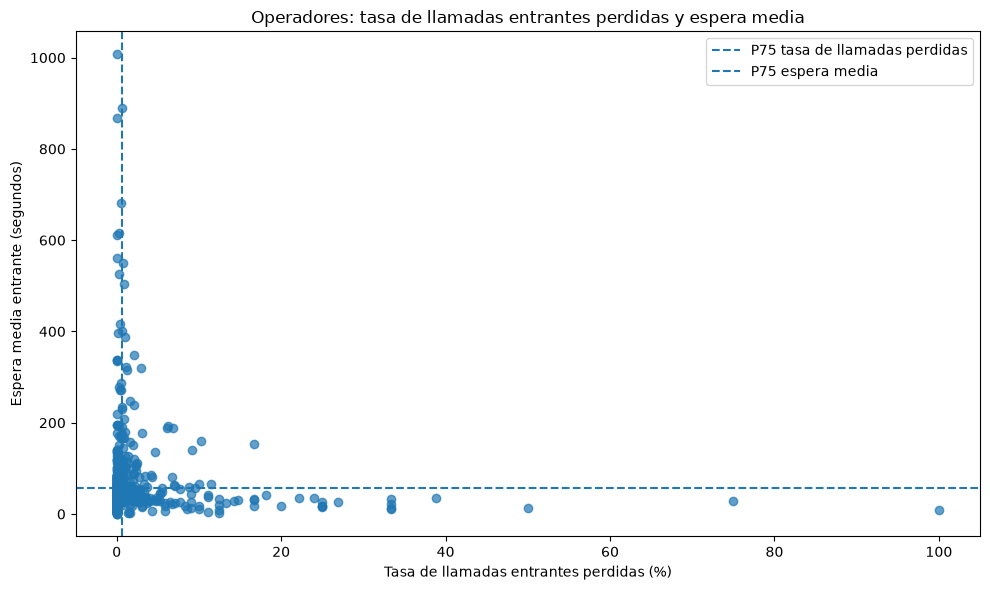

In [13]:
plot_data = operator_metrics.dropna(subset=['incoming_missed_rate', 'mean_incoming_wait']).copy()

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(
    plot_data['incoming_missed_rate'] * 100,
    plot_data['mean_incoming_wait'],
    alpha=0.7
)
ax.axvline(missed_rate_threshold * 100, linestyle='--', label='P75 tasa de llamadas perdidas')
ax.axhline(wait_threshold, linestyle='--', label='P75 espera media')
ax.set_title('Operadores: tasa de llamadas entrantes perdidas y espera media')
ax.set_xlabel('Tasa de llamadas entrantes perdidas (%)')
ax.set_ylabel('Espera media entrante (segundos)')
ax.legend()
plt.tight_layout()
plt.show()

## 7. Incorporar la información de clientes:

In [14]:
# Agregar el plan tarifario al dataset de llamadas.
calls_with_clients = calls.merge(
    client_info[['user_id', 'tariff_plan', 'date_start']],
    on='user_id',
    how='left',
    validate='many_to_one'
)

print('Porcentaje de registros de llamadas sin plan tarifario:',
      f'{calls_with_clients["tariff_plan"].isna().mean():.2%}')
display(calls_with_clients[['user_id', 'tariff_plan', 'date_start']].head())

Porcentaje de registros de llamadas sin plan tarifario: 0.00%


,user_id,tariff_plan,date_start
0,166377,B,2019-08-01
1,166377,B,2019-08-01
2,166377,B,2019-08-01
3,166377,B,2019-08-01
4,166377,B,2019-08-01


### 7.1. Indicadores por plan tarifario:

In [15]:
incoming_clients = calls_with_clients[calls_with_clients['direction'].eq('in')].copy()

plan_summary = incoming_clients.groupby('tariff_plan', dropna=False).agg(
    incoming_calls=('calls_count', 'sum'),
    missed_calls=('calls_count', lambda s: s[incoming_clients.loc[s.index, 'missed_bool'].eq(True)].sum()),
    mean_wait_seconds=('waiting_time', 'mean'),
    median_wait_seconds=('waiting_time', 'median'),
    records=('calls_count', 'size')
)
plan_summary['missed_call_rate'] = (
    plan_summary['missed_calls'] / plan_summary['incoming_calls'].replace(0, np.nan)
)
display(plan_summary.sort_values('incoming_calls', ascending=False))

,incoming_calls,missed_calls,mean_wait_seconds,median_wait_seconds,records,missed_call_rate
tariff_plan,,,,,,
A,90793,58763,154.51,41.00,4705,0.65
C,54035,20443,98.74,36.00,8398,0.38
B,53017,25117,136.34,36.00,6900,0.47


## 8. Pruebas de hipótesis estadísticas:

In [16]:
alpha = 0.05

plan_record_counts = incoming_clients['tariff_plan'].value_counts(dropna=True)
top_plans = plan_record_counts.head(2).index.tolist()

if len(top_plans) < 2:
    print('No hay al menos dos planes tarifarios con datos para realizar la prueba.')
else:
    plan_a, plan_b = top_plans
    wait_a = incoming_clients.loc[
        incoming_clients['tariff_plan'].eq(plan_a), 'waiting_time'
    ].dropna()
    wait_b = incoming_clients.loc[
        incoming_clients['tariff_plan'].eq(plan_b), 'waiting_time'
    ].dropna()

    print(f'Planes comparados: {plan_a} (n={len(wait_a)}) vs {plan_b} (n={len(wait_b)})')
    print(f'Mediana de espera — {plan_a}: {wait_a.median():.2f} segundos')
    print(f'Mediana de espera — {plan_b}: {wait_b.median():.2f} segundos')

    if len(wait_a) >= 2 and len(wait_b) >= 2:
        u_stat, p_value = stats.mannwhitneyu(wait_a, wait_b, alternative='two-sided')
        print(f'Estadístico U: {u_stat:.2f}')
        print(f'Valor p: {p_value:.6g}')
        if p_value < alpha:
            print('Decisión: se rechaza H₀. Hay evidencia de una diferencia en las distribuciones del tiempo de espera.')
        else:
            print('Decisión: no se rechaza H₀. No hay evidencia suficiente de una diferencia en las distribuciones del tiempo de espera.')
    else:
        print('No hay suficientes observaciones por grupo para ejecutar la prueba.')

Planes comparados: C (n=8398) vs B (n=6900)
Mediana de espera — C: 36.00 segundos
Mediana de espera — B: 36.00 segundos
Estadístico U: 28606839.00
Valor p: 0.17778
Decisión: no se rechaza H₀. No hay evidencia suficiente de una diferencia en las distribuciones del tiempo de espera.


In [17]:
if len(top_plans) < 2:
    print('No hay al menos dos planes tarifarios con datos para realizar la prueba.')
else:
    test_data = incoming_clients[
        incoming_clients['tariff_plan'].isin(top_plans) &
        incoming_clients['missed_bool'].notna()
    ].copy()

    contingency = pd.crosstab(test_data['tariff_plan'], test_data['missed_bool'])
    display(contingency)

    if contingency.shape == (2, 2) and (contingency.to_numpy().sum(axis=0) > 0).all():
        chi2, p_value, dof, expected = stats.chi2_contingency(contingency)
        print(f'Estadístico chi-cuadrado: {chi2:.4f}')
        print(f'Grados de libertad: {dof}')
        print(f'Valor p: {p_value:.6g}')
        print('Frecuencias esperadas:')
        display(pd.DataFrame(expected, index=contingency.index, columns=contingency.columns))

        if (expected < 5).any():
            print('Advertencia: al menos una frecuencia esperada es menor que 5; interpreta la aproximación chi-cuadrado con cautela.')
        if p_value < alpha:
            print('Decisión: se rechaza H₀. Hay evidencia de asociación entre plan tarifario y estado de llamada perdida.')
        else:
            print('Decisión: no se rechaza H₀. No hay evidencia suficiente de asociación entre plan tarifario y estado de llamada perdida.')
    else:
        print('La tabla de contingencia no tiene las dimensiones necesarias para esta prueba.')

missed_bool,False,True
tariff_plan,,
B,3949,2951
C,4920,3478


Estadístico chi-cuadrado: 2.7928
Grados de libertad: 1
Valor p: 0.0946881
Frecuencias esperadas:


missed_bool,False,True
tariff_plan,,
B,"4,000.27","2,899.73"
C,"4,868.73","3,529.27"


Decisión: no se rechaza H₀. No hay evidencia suficiente de asociación entre plan tarifario y estado de llamada perdida.


## 9. Conclusiones automáticas para apoyar la redacción:

In [18]:
print('RESUMEN DEL ANÁLISIS')
print('---------------------')
print(f'Registros de llamadas analizados: {len(calls):,}')
print(f'Clientes registrados en la tabla de clientes: {client_info["user_id"].nunique():,}')
print(f'Operadores con actividad identificada: {operator_metrics.index.nunique():,}')
print(f'Operadores con 2 o más señales de posible ineficacia: {int(operator_metrics["potentially_inefficient"].sum()):,}')

if len(operator_review):
    top_review = operator_review[operator_review['potentially_inefficient']].head(10)
    if len(top_review):
        print('\\nOperadores prioritarios para revisión:')
        display(top_review)
    else:
        print('\\nNingún operador alcanzó dos señales con los umbrales exploratorios definidos.')

print('\\nRecordatorio: los umbrales son relativos a esta muestra y deben validarse con reglas operativas reales.')

RESUMEN DEL ANÁLISIS
---------------------
Registros de llamadas analizados: 49,002
Clientes registrados en la tabla de clientes: 732
Operadores con actividad identificada: 1,092
Operadores con 2 o más señales de posible ineficacia: 97
\nOperadores prioritarios para revisión:


,operator_id,incoming_calls,incoming_missed_calls,incoming_missed_rate_pct,mean_incoming_wait,median_incoming_wait,outgoing_calls,high_missed_rate,long_incoming_wait,low_outgoing_volume,inefficiency_signals,potentially_inefficient
439,"919,206.00",926.00,9.00,0.97,388.05,457.00,1.00,True,True,True,3,True
465,"919,554.00","1,182.00",11.00,0.93,503.16,539.50,11.00,True,True,True,3,True
438,"919,204.00","1,167.00",9.00,0.77,550.94,634.00,9.00,True,True,True,3,True
242,"904,344.00",4.00,3.00,75.00,27.50,27.50,5.00,True,False,True,2,True
675,"937,368.00",22.00,4.00,18.18,40.85,25.00,10.00,True,False,True,2,True
823,"944,226.00",180.00,30.00,16.67,153.58,95.50,109.00,True,True,False,2,True
263,"905,862.00",102.00,15.00,14.71,31.49,15.00,1.00,True,False,True,2,True
812,"941,844.00",7.00,1.00,14.29,29.25,24.50,11.00,True,False,True,2,True
419,"918,888.00",8.00,1.00,12.50,9.38,6.50,3.00,True,False,True,2,True
557,"926,872.00",24.00,3.00,12.50,1.46,1.00,7.00,True,False,True,2,True


\nRecordatorio: los umbrales son relativos a esta muestra y deben validarse con reglas operativas reales.


## 10. Exportar tablas de resultados: 

In [19]:
OUTPUT_DIR = Path('resultados_telecom')
OUTPUT_DIR.mkdir(exist_ok=True)

operator_review.to_csv(OUTPUT_DIR / 'indicadores_por_operador.csv', index=False)
plan_summary.to_csv(OUTPUT_DIR / 'indicadores_por_plan_tarifario.csv')
daily_calls.rename('calls_count').to_csv(OUTPUT_DIR / 'llamadas_por_dia.csv')

print('Archivos guardados en:', OUTPUT_DIR.resolve())
print('- indicadores_por_operador.csv')
print('- indicadores_por_plan_tarifario.csv')
print('- llamadas_por_dia.csv')

Archivos guardados en: C:\Users\quist\OneDrive\Documentos\Tripleten\FINAL_PROJECT_DA\Telecomunicaciones- operadores ineficaces\resultados_telecom
- indicadores_por_operador.csv
- indicadores_por_plan_tarifario.csv
- llamadas_por_dia.csv


## 11. Conclusiones del proyecto:

# 11. Conclusiones del proyecto

### 11.1. Calidad y preparación de los datos:

El análisis comenzó con dos conjuntos de datos: uno con 53,902 registros de llamadas y otro con información de 732 clientes. Durante la revisión inicial se identificaron 4,900 registros duplicados en la tabla de llamadas, los cuales se eliminaron para evitar contabilizar dos veces los mismos registros. Después de la limpieza, se trabajó con 49,002 registros de llamadas.

También se identificaron valores ausentes en las variables `operator_id` e `internal`. Después de eliminar los duplicados, 7,456 registros no tenían un operador identificado y 110 registros no contenían información sobre si la llamada era interna. Estos casos se conservaron cuando fue posible utilizarlos en otros análisis, pero limitaron la capacidad de atribuir determinadas llamadas a un operador específico.

La preparación incluyó la conversión de fechas y variables numéricas, la normalización de indicadores booleanos y el cálculo del tiempo de espera mediante la diferencia entre `total_call_duration` y `call_duration`. Estas transformaciones permitieron realizar comparaciones y construir indicadores de desempeño.

### 11.2. Principales hallazgos del análisis exploratorio:

El análisis del volumen de llamadas mostró que las llamadas salientes concentraron 608,864 llamadas contabilizadas, mientras que las entrantes sumaron 197,845. Esto indica que la actividad saliente representó aproximadamente el 75.5 % del volumen total registrado, por lo que constituye una parte importante de las operaciones del servicio.

En cuanto al tipo de comunicación, las llamadas externas concentraron 791,829 llamadas contabilizadas, mientras que las internas representaron 14,655. La actividad estuvo orientada principalmente a las comunicaciones externas, aunque las llamadas internas también forman parte de la operación.

Respecto a la duración, el promedio fue de 866.28 segundos y la mediana de 37 segundos. La diferencia entre ambas medidas indica una distribución asimétrica, en la que algunas llamadas de duración considerablemente mayor elevan el promedio. Por esta razón, la mediana resulta útil para describir la duración típica de los registros.

El análisis diario mostró un promedio de 6,779.07 llamadas contabilizadas por día, con una mediana de 5,096 y un máximo de 18,222. Esta variación refleja diferencias importantes en el volumen de actividad entre los días analizados, por lo que sería conveniente revisar los periodos de mayor demanda para mejorar la distribución de recursos.

En las llamadas entrantes se contabilizaron 197,845 llamadas, de las cuales 104,323 correspondieron a registros marcados como perdidos. Esto equivale aproximadamente al 52.7 % del volumen entrante contabilizado mediante `calls_count`. El resultado representa una señal relevante que requiere investigación operativa, aunque debe interpretarse considerando cómo se registran y agrupan las llamadas en la base de datos.

El tiempo de espera promedio de las llamadas entrantes fue de 124.83 segundos, mientras que la mediana fue de 37 segundos. Esta diferencia sugiere que algunos registros presentan tiempos de espera elevados y refuerza la importancia de analizar el comportamiento por operador y revisar los casos extremos.

### 11.3. Identificación de operadores con posibles problemas de desempeño:

Para identificar operadores que requieren revisión, se construyeron indicadores relacionados con la tasa de llamadas entrantes perdidas, el tiempo de espera promedio y el volumen de llamadas salientes.

Se utilizaron como referencias exploratorias el percentil 75 de la tasa de llamadas perdidas, equivalente al 0.67 %, el percentil 75 del tiempo de espera promedio, equivalente a 58 segundos, y el percentil 25 del volumen de llamadas salientes, equivalente a 11 llamadas.

Con estos criterios se identificaron 97 operadores con al menos dos señales de posible ineficacia, de un total de 1,092 operadores con actividad identificada en los registros analizados.

Entre los casos prioritarios destacaron los siguientes:

- **Operador 919206:** registró 926 llamadas entrantes, 9 llamadas perdidas contabilizadas, una tasa de llamadas perdidas del 0.97 %, un tiempo de espera promedio de 388.05 segundos y una sola llamada saliente.
- **Operador 919554:** registró 1,182 llamadas entrantes, 11 llamadas perdidas contabilizadas, una tasa del 0.93 %, un tiempo de espera promedio de 503.16 segundos y 11 llamadas salientes.
- **Operador 919204:** registró 1,167 llamadas entrantes, 9 llamadas perdidas contabilizadas, una tasa del 0.77 %, un tiempo de espera promedio de 550.94 segundos y 9 llamadas salientes.

Estos tres operadores presentaron simultáneamente las tres señales definidas en el análisis. Sus tiempos de espera y su actividad saliente justifican una revisión más detallada, especialmente porque el volumen de llamadas entrantes registrado permite contextualizar sus indicadores.

Sin embargo, estos resultados no demuestran por sí mismos que los operadores sean ineficaces. Antes de tomar decisiones, es necesario verificar sus horarios, funciones asignadas, carga de trabajo y condiciones de atención. Asimismo, algunos operadores presentan pocos registros, por lo que sus tasas pueden variar considerablemente con un número reducido de llamadas.

### 11.4. Resultados de las pruebas de hipótesis estadísticas:

Se realizaron dos pruebas estadísticas para explorar posibles diferencias entre los planes tarifarios B y C.

**Primera prueba: diferencias en los tiempos de espera**

Se aplicó la prueba U de Mann–Whitney para comparar las distribuciones de los tiempos de espera de las llamadas entrantes entre los planes C y B.

Las medianas de ambos grupos fueron de 36 segundos. El estadístico U fue de 28,606,839 y el valor p fue de 0.17778.

Como el valor p fue superior al nivel de significancia de 0.05, no se rechazó la hipótesis nula. Por lo tanto, no se encontró evidencia estadística suficiente para afirmar que las distribuciones de los tiempos de espera sean diferentes entre los dos planes analizados.

**Segunda prueba: asociación entre el plan tarifario y las llamadas perdidas**

Se aplicó la prueba chi-cuadrado de independencia para evaluar si existía una asociación entre el plan tarifario y el estado de llamada perdida.

El estadístico chi-cuadrado fue de 2.7928, con un valor p de 0.0946881. Debido a que el valor p también fue superior a 0.05, no se rechazó la hipótesis nula.

En consecuencia, no se encontró evidencia estadística suficiente de una asociación entre el plan tarifario y el estado de llamada perdida en los registros comparados.

Estos resultados no demuestran que ambos planes tengan un comportamiento idéntico. Únicamente indican que, con los datos y las pruebas utilizadas, no se obtuvo evidencia suficiente para sostener las diferencias o la asociación planteadas.

### 11.5. Recomendaciones:

A partir de los resultados, se proponen las siguientes acciones:

1. **Revisar los operadores prioritarios.** Analizar los casos que presentan simultáneamente una tasa elevada de llamadas perdidas, tiempos de espera prolongados y poca actividad saliente, verificando primero sus responsabilidades y condiciones de trabajo.
2. **Investigar las llamadas entrantes perdidas.** Examinar los periodos, clientes y condiciones operativas en los que se concentra este comportamiento para identificar posibles problemas de asignación o atención.
3. **Monitorear los tiempos de espera.** Utilizar indicadores como la media, la mediana y los percentiles para identificar demoras recurrentes sin depender únicamente del promedio.
4. **Validar los criterios de desempeño.** Establecer umbrales oficiales de llamadas perdidas, tiempos de espera y actividad saliente, considerando el tipo de función de cada operador.
5. **Mejorar la calidad de los registros.** Investigar los registros sin identificador de operador y los valores ausentes en el tipo de llamada interna o externa, ya que reducen la precisión de ciertos análisis.
6. **Profundizar en las diferencias operativas.** Incorporar análisis por cliente, fecha, dirección de llamada y carga de trabajo para comprender mejor los factores asociados con el desempeño.

### 11.6. Conclusión general:

El proyecto permitió examinar el comportamiento de las llamadas del servicio CallMeMaybe, identificar patrones de actividad y construir indicadores para detectar operadores que requieren una revisión de su desempeño.

Los resultados mostraron un volumen importante de llamadas entrantes marcadas como perdidas, diferencias considerables en los tiempos de espera y una variación relevante en la actividad diaria. Asimismo, el análisis por operador identificó 97 casos con al menos dos señales exploratorias de posible ineficacia, entre los que destacaron los operadores 919206, 919554 y 919204 por presentar las tres señales definidas.

Por otra parte, las pruebas estadísticas no encontraron evidencia suficiente de diferencias en las distribuciones de los tiempos de espera ni de asociación entre el plan tarifario y el estado de llamada perdida al comparar los planes B y C.

En conclusión, el análisis de datos proporciona una base útil para orientar la supervisión operativa y priorizar investigaciones sobre las llamadas perdidas y los tiempos de espera. No obstante, la clasificación de los operadores debe complementarse con información sobre sus funciones, horarios y objetivos de servicio. De esta manera, CallMeMaybe podría utilizar los resultados como punto de partida para mejorar la distribución de llamadas, fortalecer el seguimiento del desempeño y contribuir a una atención telefónica más eficiente.